# GitHub Issue Triage Assistant

**Lohith Regalla (lr103) | RCEL 506 | Final project notebook**

## Question and value

Can the title and description of a newly opened scikit-learn issue help a maintainer decide whether it is a **Bug** or a **Feature Request**? The app offers a preliminary suggestion for human review. Its possible value is less first-pass sorting work. This notebook does not measure staff time saved.

The target is based on the repository's labels at collection time. **Bug** maps to Bug. **Feature Request** maps to Enhancement or New Feature, following the repository's [label guide](https://github.com/scikit-learn/scikit-learn/wiki/labels). Issues with neither category or with both categories are outside this binary experiment.

The collection covers issues created from January 2024 through October 2026. It queries every month and checks each page count. Email addresses in issue text were redacted before saving. The saved data makes this notebook reproducible without a GitHub token. This is a repository-specific evaluation, not a promise of reliable automatic labeling.

In [1]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
import matplotlib.pyplot as plt
import pandas as pd

DATA_NAME = "scikit_learn_issues_date_cohort_labeled.csv"
DATA_PATH = Path("data") / DATA_NAME
if not DATA_PATH.exists():
    DATA_PATH = Path(DATA_NAME)
    DATA_PATH.write_bytes(urlopen("https://raw.githubusercontent.com/LOHITHR29/github-issue-triage-assistant-rcel506/main/data/" + DATA_NAME).read())

EXPECTED_SHA256 = "2150aac51bb817054f72e9acb04db7c7d2bddd14806510f1a6aa83994706f207"
actual_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_hash == EXPECTED_SHA256, "The CSV does not match the audited project data"

AUDIT_PATH = Path("data/collection_audit.json")
if AUDIT_PATH.exists():
    audit = json.loads(AUDIT_PATH.read_text())
else:
    audit = json.loads(urlopen("https://raw.githubusercontent.com/LOHITHR29/github-issue-triage-assistant-rcel506/main/data/collection_audit.json").read())
print("Data file:", DATA_PATH)
print("SHA-256:", actual_hash)
print("Collected at:", audit["retrieved_at"])

Data file: data/scikit_learn_issues_date_cohort_labeled.csv
SHA-256: 2150aac51bb817054f72e9acb04db7c7d2bddd14806510f1a6aa83994706f207
Collected at: 2026-10-31T17:09:02.682069+00:00


## 1. Read and verify the data

The extraction used GitHub issue search with `is:issue`, so pull requests are excluded by the query. It fetched every page for each creation month and rejected any incomplete month. Labels are a snapshot at retrieval, so a later label change can affect the historical target. The raw cohort and month-level audit are bundled in the repository.

In [2]:
"""Reproducible, repository-specific Bug versus Feature Request triage."""

from __future__ import annotations

import re
from dataclasses import dataclass
from pathlib import Path

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.pipeline import Pipeline


LABELS = ("Bug", "Feature Request")
TARGET_WORDS = re.compile(
    r"\b(?:bug\s+reports?|new\s+features?|feature\s+requests?|bugs?|features?|enhancements?|enh)\b",
    flags=re.IGNORECASE,
)
TEMPLATE_HEADERS = re.compile(r"(?m)^\s*#{1,6}\s+[^\n]*$")
VERSIONS_SECTION = re.compile(
    r"(?ims)^\s*#{1,6}\s+versions?\s*$.*?(?=^\s*#{1,6}\s|\Z)"
)
NO_RESPONSE = re.compile(r"(?im)^\s*_?no response_?\s*$")
SPACE = re.compile(r"\s+")


def clean_text(title: object, body: object) -> str:
    """Use only title and body, with explicit target words and common headers removed."""
    parts = [part if isinstance(part, str) else "" for part in (title, body)]
    text = "\n".join(parts)
    text = VERSIONS_SECTION.sub(" ", text)
    text = NO_RESPONSE.sub(" ", text)
    text = TEMPLATE_HEADERS.sub(" ", text)
    text = TARGET_WORDS.sub(" ", text)
    text = re.sub(r"(?m)^\s*[:;]\s*", " ", text)
    return SPACE.sub(" ", text).strip().lower()


def load_issues(path: Path) -> pd.DataFrame:
    issues = pd.read_csv(path)
    required = {"issue_number", "title", "body", "created_at", "issue_type"}
    missing = required - set(issues.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if issues["issue_number"].isna().any() or issues["issue_number"].duplicated().any():
        raise ValueError("Issue numbers must be present and unique")
    if issues["title"].isna().any():
        raise ValueError("Issue titles must be present")
    if set(issues["issue_type"]) != set(LABELS):
        raise ValueError("Expected exactly Bug and Feature Request labels")
    issues["created_at"] = pd.to_datetime(issues["created_at"], utc=True, errors="raise")
    issues["text"] = [clean_text(t, b) for t, b in zip(issues["title"], issues["body"])]
    if issues["text"].eq("").any():
        raise ValueError("One or more issues have no usable title or body text")
    return issues.sort_values(["created_at", "issue_number"]).reset_index(drop=True)


@dataclass
class Result:
    issues: pd.DataFrame
    train: pd.DataFrame
    test: pd.DataFrame
    model: Pipeline
    predictions: list[str]
    baseline_predictions: list[str]
    metrics: dict


def fit_and_evaluate(issues: pd.DataFrame) -> Result:
    """Fit text and majority models on the oldest 80% only."""
    if len(issues) < 20:
        raise ValueError("At least 20 issues are required")
    split = int(len(issues) * 0.8)
    train = issues.iloc[:split].copy()
    test = issues.iloc[split:].copy()
    if train["issue_type"].nunique() != 2 or test["issue_type"].nunique() != 2:
        raise ValueError("Both classes must be present in each split")
    model = Pipeline(
        [
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95,
                                      max_features=30000, sublinear_tf=True)),
            ("logistic_regression", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                       solver="liblinear")),
        ]
    )
    model.fit(train["text"], train["issue_type"])
    predictions = model.predict(test["text"]).tolist()
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit([[0]] * len(train), train["issue_type"])
    baseline_predictions = baseline.predict([[0]] * len(test)).tolist()
    metrics = {
        "train_count": len(train),
        "test_count": len(test),
        "train_labels": train["issue_type"].value_counts().to_dict(),
        "test_labels": test["issue_type"].value_counts().to_dict(),
        "train_end": train["created_at"].max().isoformat(),
        "test_start": test["created_at"].min().isoformat(),
        "test_end": test["created_at"].max().isoformat(),
        "model": _scores(test["issue_type"], predictions),
        "baseline": _scores(test["issue_type"], baseline_predictions),
    }
    return Result(issues, train, test, model, predictions, baseline_predictions, metrics)


def _scores(actual: pd.Series, predicted: list[str]) -> dict:
    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=LABELS, zero_division=0
    )
    return {
        "accuracy": round(float(accuracy_score(actual, predicted)), 4),
        "macro_f1": round(float(f1_score(actual, predicted, labels=LABELS,
                                         average="macro", zero_division=0)), 4),
        "per_class": {
            label: {"precision": round(float(precision[i]), 4),
                    "recall": round(float(recall[i]), 4),
                    "f1": round(float(f1[i]), 4),
                    "support": int(support[i])}
            for i, label in enumerate(LABELS)
        },
        "confusion_matrix": confusion_matrix(actual, predicted, labels=LABELS).tolist(),
    }


def predict_issue(result: Result, title: str, body: str) -> dict:
    text = clean_text(title, body)
    if len(text) < 10:
        raise ValueError("Enter a descriptive title or body with at least 10 usable characters")
    probabilities = result.model.predict_proba([text])[0]
    classes = result.model.classes_.tolist()
    return {
        "suggested_label": classes[int(probabilities.argmax())],
        "model_probabilities": {label: round(float(probabilities[classes.index(label)]), 3)
                                for label in LABELS},
    }

In [3]:
issues = load_issues(DATA_PATH)
print("All issues collected:", audit["raw_count"])
print("Excluded, neither target:", audit["excluded"]["neither_target"])
print("Excluded, both categories:", audit["excluded"]["ambiguous"])
print("Usable binary issues:", len(issues))
print("Unique issue numbers:", issues.issue_number.nunique())
print("Date range:", issues.created_at.min(), "to", issues.created_at.max())
print("Class counts:\n", issues.issue_type.value_counts())
print("Missing values:\n", issues[["title", "body", "created_at", "issue_type"]].isna().sum())
assert len(issues) == audit["labeled_count"]
assert len(issues) + sum(audit["excluded"].values()) == audit["raw_count"]
display(issues[["issue_number", "created_at", "title", "issue_type"]].head())

All issues collected: 1757
Excluded, neither target: 907
Excluded, both categories: 3
Usable binary issues: 847
Unique issue numbers: 847
Date range: 2024-01-02 09:14:42+00:00 to 2026-10-28 11:05:50+00:00
Class counts:
 issue_type
Bug                568
Feature Request    279
Name: count, dtype: int64
Missing values:
 title         0
body          2
created_at    0
issue_type    0
dtype: int64


,issue_number,created_at,title,issue_type
0,28041,2024-01-02 09:14:42+00:00,Random object not being passed from to Kmeans,Bug
1,28046,2024-01-02 16:13:24+00:00,Log Loss gradient and hessian returns NaN for ...,Bug
2,28050,2024-01-02 17:52:28+00:00,function `_check_pos_label_consistency()` appl...,Feature Request
3,28055,2024-01-03 03:20:09+00:00,Infinite Loop in K-means when relocating empty...,Bug
4,28059,2024-01-03 21:21:14+00:00,ENH: Random Forest Classifier oob scaling/para...,Feature Request


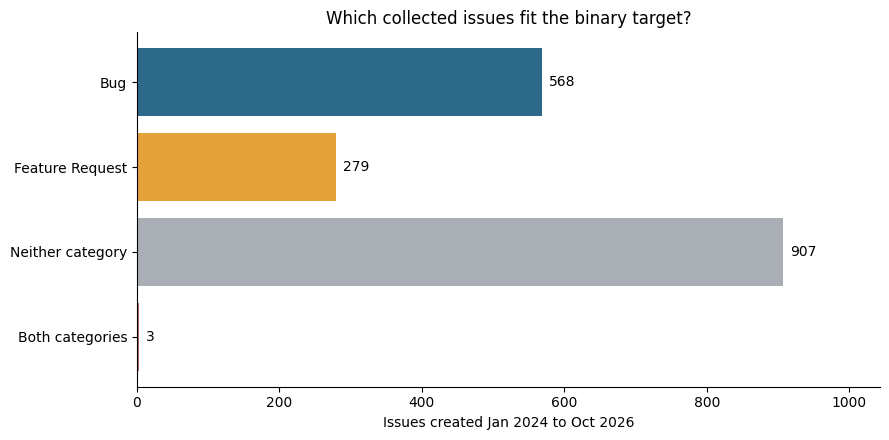

In [4]:
coverage = pd.Series({
    "Bug": audit["class_counts"]["Bug"],
    "Feature Request": audit["class_counts"]["Feature Request"],
    "Neither category": audit["excluded"]["neither_target"],
    "Both categories": audit["excluded"]["ambiguous"],
})
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#2d6a8a", "#e5a23b", "#a9afb4", "#b76565"]
bars = ax.barh(coverage.index[::-1], coverage.values[::-1], color=colors[::-1])
ax.bar_label(bars, padding=5)
ax.set_xlim(0, coverage.max() * 1.15)
ax.set_xlabel("Issues created Jan 2024 to Oct 2026")
ax.set_title("Which collected issues fit the binary target?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

More than half of the collected issues have neither target label. The app is therefore a **binary suggestion tool for the defined subset**, and a maintainer must route other issue types.

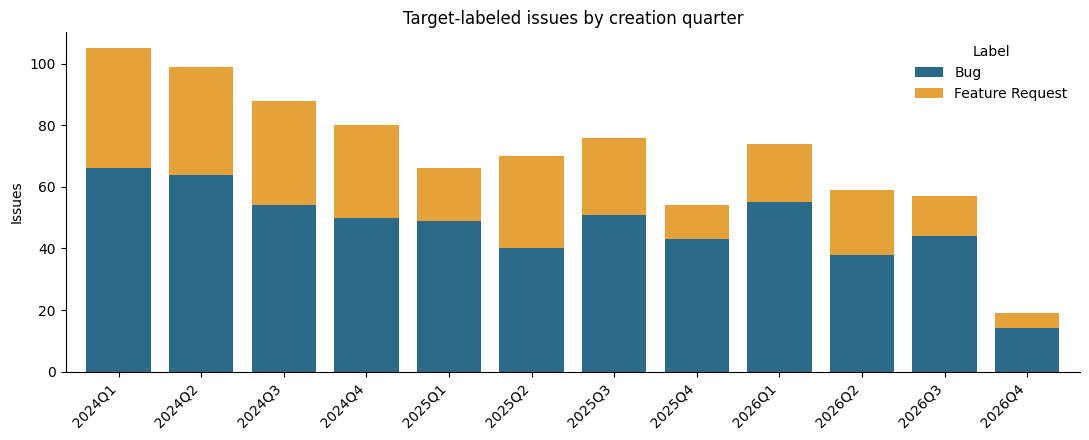

issue_type,Bug,Feature Request
quarter,,
2024Q1,66,39
2024Q2,64,35
2024Q3,54,34
2024Q4,50,30
2025Q1,49,17
2025Q2,40,30
2025Q3,51,25
2025Q4,43,11
2026Q1,55,19


In [5]:
by_quarter = (issues.assign(quarter=issues.created_at.dt.tz_localize(None).dt.to_period("Q").astype(str))
             .groupby(["quarter", "issue_type"]).size().unstack(fill_value=0)
             .reindex(columns=LABELS, fill_value=0))
ax = by_quarter.plot(kind="bar", stacked=True, figsize=(11, 4.5),
                     color=["#2d6a8a", "#e5a23b"], width=0.78)
ax.set_title("Target-labeled issues by creation quarter")
ax.set_xlabel("")
ax.set_ylabel("Issues")
ax.legend(title="Label", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(by_quarter)

## 2. Train and test in time order

The oldest 80% of usable issues are training data and the newest 20% are held out for testing. TF-IDF learns its vocabulary only from training text inside the pipeline. The model uses title and body after removing explicit target words, issue-template headings, the generic “No response” placeholder, and the automatic Versions section. Dates, labels, IDs, and other metadata are never model inputs.

The majority-class classifier uses training labels only. Macro F1 gives equal weight to each class.

In [6]:
result = fit_and_evaluate(issues)
print("Training:", result.metrics["train_count"], result.metrics["train_labels"])
print("Test:", result.metrics["test_count"], result.metrics["test_labels"])
print("Train ends:", result.metrics["train_end"])
print("Test starts:", result.metrics["test_start"])
scores = pd.DataFrame({
    "Majority baseline": result.metrics["baseline"],
    "TF-IDF + Logistic Regression": result.metrics["model"],
}).loc[["accuracy", "macro_f1"]]
display(scores)
display(pd.DataFrame(result.metrics["model"]["per_class"]).T)

Training: 677 {'Bug': 449, 'Feature Request': 228}
Test: 170 {'Bug': 119, 'Feature Request': 51}
Train ends: 2026-02-17T23:08:02+00:00
Test starts: 2026-02-18T10:14:47+00:00


,Majority baseline,TF-IDF + Logistic Regression
accuracy,0.7,0.8824
macro_f1,0.4118,0.8702


,precision,recall,f1,support
Bug,0.9806,0.8487,0.9099,119.0
Feature Request,0.7313,0.9608,0.8305,51.0


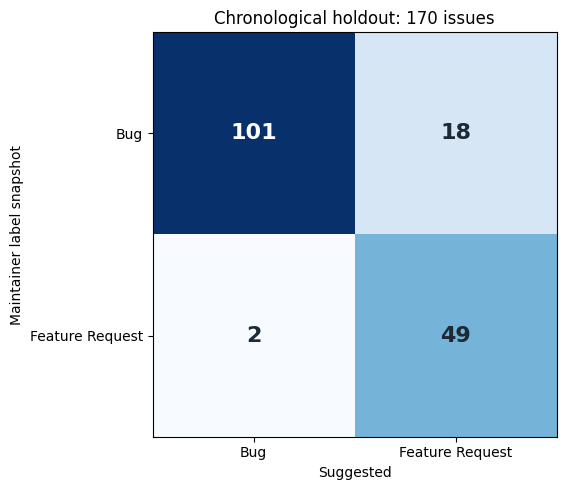

In [7]:
matrix = pd.DataFrame(result.metrics["model"]["confusion_matrix"], index=LABELS, columns=LABELS)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrix.values, cmap="Blues")
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(matrix.iloc[row, col]), ha="center", va="center",
                color="white" if matrix.iloc[row, col] > matrix.values.max() / 2 else "#1d2a35",
                fontsize=16, fontweight="bold")
ax.set_xticks(range(2), LABELS)
ax.set_yticks(range(2), LABELS)
ax.set_xlabel("Suggested")
ax.set_ylabel("Maintainer label snapshot")
ax.set_title("Chronological holdout: 170 issues")
plt.tight_layout()
plt.show()

In [8]:
errors = result.test.loc[[actual != predicted for actual, predicted in
                          zip(result.test.issue_type, result.predictions)],
                         ["issue_number", "created_at", "title", "issue_type", "source_url"]].copy()
errors["suggested"] = [prediction for actual, prediction in
                       zip(result.test.issue_type, result.predictions) if actual != prediction]
print("Errors:", len(errors))
display(errors.head(10))

# Sensitivity check: use only titles, with the same split and model settings.
title_data = issues.copy()
title_data["text"] = [clean_text(title, "") for title in title_data.title]
title_result = fit_and_evaluate(title_data)
print("Title-only macro F1:", title_result.metrics["model"]["macro_f1"])
print("Title and body macro F1:", result.metrics["model"]["macro_f1"])

Errors: 20


,issue_number,created_at,title,issue_type,source_url,suggested
743,34035,2026-05-18 03:31:12+00:00,Keyword-Only arguments in `train_test_split`,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
750,34074,2026-05-21 13:09:49+00:00,KMeans can skip final label reassignment after...,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
751,34075,2026-05-21 13:35:08+00:00,allow to skip some attributes from the HTML re...,Feature Request,https://github.com/scikit-learn/scikit-learn/i...,Bug
755,34139,2026-05-27 19:04:52+00:00,Handling of classes with all-zero weights,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
766,34312,2026-06-16 13:57:08+00:00,"`CalibratedClassifierCV(method=""sigmoid"")` sho...",Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
770,34351,2026-06-21 02:56:48+00:00,Reconsider zero-affinity row fallback in Label...,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
774,34477,2026-07-14 14:36:14+00:00,Infinite Recursion when using a mock as param ...,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
776,34529,2026-07-20 18:56:49+00:00,Failing wheel builds removed sklearn from anac...,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request
790,34672,2026-08-07 08:34:06+00:00,PCA does not discard singular values equal to ...,Feature Request,https://github.com/scikit-learn/scikit-learn/i...,Bug
796,34738,2026-08-12 14:58:48+00:00,PytestRemovedIn10Warning (pytest version 9.1.1...,Bug,https://github.com/scikit-learn/scikit-learn/i...,Feature Request


Title-only macro F1: 0.8177
Title and body macro F1: 0.8702


## 3. Live audit and example

Change `year` below during a live review to inspect any creation year in the saved data. Rerun the cell and the count and rows will update.

In [9]:
year = 2026
year_view = issues.loc[issues.created_at.dt.year == year]
print(f"{year}: {len(year_view)} target-labeled issues")
print(year_view.issue_type.value_counts())
display(year_view[["issue_number", "created_at", "title", "issue_type"]].head(10))

2026: 209 target-labeled issues
issue_type
Bug                151
Feature Request     58
Name: count, dtype: int64


,issue_number,created_at,title,issue_type
638,32978,2026-01-01 08:38:44+00:00,janitor module conflicts with sklearn cross_va...,Bug
639,32987,2026-01-02 06:04:58+00:00,CI : Numerical flakiness in test_enet_ols_cons...,Bug
640,32989,2026-01-03 10:18:10+00:00,enet_path raises ValueError when check_input=F...,Bug
641,33002,2026-01-05 14:11:55+00:00,Downloading 20_newsgroups results in 403 error,Bug
642,33005,2026-01-05 19:57:47+00:00,HTML rendering of estimator parameters does no...,Bug
643,33032,2026-01-09 20:15:35+00:00,BUG: LinearRegression is wrong on float32 and ...,Bug
644,33034,2026-01-09 22:40:34+00:00,`KNeighborsClassifier` fails on non-numeric la...,Bug
645,33042,2026-01-10 20:26:26+00:00,Online Quantile Approximation,Feature Request
646,33044,2026-01-11 03:55:51+00:00,Degraded performance of `enet_path` due to #31882,Bug
647,33047,2026-01-12 02:40:54+00:00,⚠️ CI failed on Linux_Nightly.pylatest_pip_sci...,Bug


In [10]:
example = predict_issue(
    result,
    "Allow custom threshold in confusion matrix display",
    "I would like an option to specify a threshold when displaying predictions.",
)
print("Example suggestion for maintainer review:", example)

Example suggestion for maintainer review: {'suggested_label': 'Feature Request', 'model_probabilities': {'Bug': 0.269, 'Feature Request': 0.731}}


## Interpretation and limits

The text model improves on the majority-class baseline on this saved, chronological holdout. This supports a **proof of concept** for human-reviewed first-pass triage within scikit-learn. It does not prove that maintainer time is saved. It also does not cover unlabeled, documentation, CI, or other issue types.

Labels are the state observed at collection time, not label events reconstructed at creation. The repository's use of labels and issue templates can change. A future operational study should collect another recent cohort, verify label timing, measure reviewer effort, and test a manual-review or abstain route before any automatic labeling.

Live app: https://scikit-learn-issue-triage-lr103.streamlit.app/
Source and data: https://github.com/LOHITHR29/github-issue-triage-assistant-rcel506